In [ ]:
# weather, climate (power nasa)
# soil information - ph, texture, organic carbon, data source and resolution (Soilgrids)
# vegetation index, obs date, data quality and coverage (MODIS/Terra vegetation 16Day global 250m) (https://appeears.earthdatacloud.nasa.gov/)

In [2]:
import requests
import pandas as pd

In [3]:
BASE_URL = "https://power.larc.nasa.gov/api/temporal/daily/point"
# Example coordinates: longitude, latitude
_CHITWAN_COORDINATES = {"LAT": 27.643692887895675, "LON": 84.36065413845583}
_BHAKTAPUR_COORDINATES = {"LAT": 27.597964, "LON": 85.384573}
_BHARATPUR_COORDINATES = {"LAT": 27.676546, "LON": 84.463889}

NASA_POWER_START_DATE = "20160101"
NASA_POWER_END_DATE = "20250101"

params = {
        "parameters": "PRECTOTCORR,T2M,T2M_MAX,T2M_MIN,RH2M,WS2M,ALLSKY_SFC_SW_DWN,GWETPROF",
        "community": "AG",
        "longitude": _BHARATPUR_COORDINATES["LON"],
        "latitude": _BHARATPUR_COORDINATES["LAT"],
        "start": NASA_POWER_START_DATE,
        "end": NASA_POWER_END_DATE,
        "format": "JSON",
        "time-standard": "UTC",
    }
print(params)

{'parameters': 'PRECTOTCORR,T2M,T2M_MAX,T2M_MIN,RH2M,WS2M,ALLSKY_SFC_SW_DWN,GWETPROF', 'community': 'AG', 'longitude': 84.463889, 'latitude': 27.676546, 'start': '20160101', 'end': '20250101', 'format': 'JSON', 'time-standard': 'UTC'}


In [3]:
response = requests.get(
    BASE_URL,
    params=params,
    timeout=60
)
response.raise_for_status()
payload = response.json()
print(payload)

{'type': 'Feature', 'geometry': {'type': 'Point', 'coordinates': [84.464, 27.677, 357.81]}, 'properties': {'parameter': {'PRECTOTCORR': {'20160101': 0.0, '20160102': 0.0, '20160103': 0.0, '20160104': 0.0, '20160105': 0.0, '20160106': 0.0, '20160107': 0.0, '20160108': 0.01, '20160109': 0.0, '20160110': 0.0, '20160111': 0.0, '20160112': 0.0, '20160113': 0.0, '20160114': 0.0, '20160115': 0.0, '20160116': 0.0, '20160117': 0.0, '20160118': 0.0, '20160119': 1.23, '20160120': 1.13, '20160121': 0.1, '20160122': 0.0, '20160123': 0.0, '20160124': 0.0, '20160125': 0.0, '20160126': 0.0, '20160127': 0.0, '20160128': 0.0, '20160129': 0.0, '20160130': 0.0, '20160131': 0.0, '20160201': 0.0, '20160202': 0.0, '20160203': 0.0, '20160204': 0.0, '20160205': 0.0, '20160206': 0.06, '20160207': 0.5, '20160208': 1.24, '20160209': 0.0, '20160210': 0.0, '20160211': 0.0, '20160212': 0.0, '20160213': 0.0, '20160214': 0.0, '20160215': 0.0, '20160216': 0.0, '20160217': 0.0, '20160218': 0.0, '20160219': 0.0, '2016022

In [4]:
print("type", payload["type"])
print("geometry", payload["geometry"])
print("coordinates", payload["geometry"]["coordinates"])
df = pd.DataFrame(payload["properties"]["parameter"])
df.tail(10)

type Feature
geometry {'type': 'Point', 'coordinates': [84.464, 27.677, 357.81]}
coordinates [84.464, 27.677, 357.81]


,PRECTOTCORR,T2M,T2M_MAX,T2M_MIN,RH2M,WS2M,ALLSKY_SFC_SW_DWN,GWETPROF
20241223,0.0,17.22,23.28,12.71,60.04,1.09,12.82,0.52
20241224,0.0,17.67,23.21,12.88,65.88,1.07,9.36,0.52
20241225,0.0,18.01,24.01,14.31,69.92,0.91,11.10,0.52
20241226,0.0,17.70,24.32,13.55,66.06,1.28,13.52,0.51
20241227,0.0,18.70,24.88,14.14,56.46,1.13,14.26,0.51
20241228,0.0,16.96,21.52,13.87,66.75,0.62,5.22,0.51
20241229,0.0,17.92,24.30,13.35,70.01,1.06,12.65,0.51
20241230,0.0,16.76,22.69,12.75,74.24,1.13,7.43,0.51
20241231,0.0,15.47,22.33,11.39,70.13,1.19,11.32,0.50
20250101,0.0,14.94,21.94,10.90,60.00,1.09,8.04,0.50


In [5]:
df.index.name = "date"
df = df.reset_index()
df["date"] = pd.to_datetime(
    df["date"],
    format="%Y%m%d",
    errors="raise"
)

In [6]:
df = df.rename(
    columns={
            "PRECTOTCORR": "precip",
            "T2M": "tmean",
            "T2M_MAX": "tmax",
            "T2M_MIN": "tmin",
            "RH2M": "rh",
            "WS2M": "wind",
            "ALLSKY_SFC_SW_DWN": "rs",
            "GWETPROF": "wet",
    }
)
df = df.sort_values("date").reset_index(drop=True)

In [7]:
df.isna().sum()

date      0
precip    0
tmean     0
tmax      0
tmin      0
rh        0
wind      0
rs        0
wet       0
dtype: int64

In [8]:
df

,date,precip,tmean,tmax,tmin,rh,wind,rs,wet
0,2016-01-01,0.0,17.04,23.99,11.20,38.84,1.14,13.59,0.44
1,2016-01-02,0.0,16.71,24.43,11.09,37.42,1.14,14.44,0.43
2,2016-01-03,0.0,16.33,23.75,11.21,36.24,1.18,12.83,0.43
3,2016-01-04,0.0,17.09,24.08,11.69,35.35,1.13,12.33,0.43
4,2016-01-05,0.0,16.94,24.20,12.74,35.65,1.12,12.99,0.43
...,...,...,...,...,...,...,...,...,...
3284,2024-12-28,0.0,16.96,21.52,13.87,66.75,0.62,5.22,0.51
3285,2024-12-29,0.0,17.92,24.30,13.35,70.01,1.06,12.65,0.51
3286,2024-12-30,0.0,16.76,22.69,12.75,74.24,1.13,7.43,0.51
3287,2024-12-31,0.0,15.47,22.33,11.39,70.13,1.19,11.32,0.50


In [9]:
from pathlib import Path
_POWER_CSV_FILENAME = 'nasa_power.csv'
cleaned_csv_path = Path().resolve().parent / "data" / "Crop" / "cleaned"
df.to_csv(f"{cleaned_csv_path}/{_POWER_CSV_FILENAME}.csv", index=False)

In [6]:

import numpy as np
import pandas as pd
import rasterio
from rasterio.warp import transform

# SoilGrids property metadata.
# Scale factors follow ISRIC's SoilGrids documentation.
soil_properties = {
    "phh2o": {"depth": "30-60cm", "scale": 10, "unit": "pH"},
    "soc": {"depth": "30-60cm", "scale": 10, "unit": "g/kg"},
    "clay": {"depth": "30-60cm", "scale": 10, "unit": "%"},
    "sand": {"depth": "30-60cm", "scale": 10, "unit": "%"},
    "silt": {"depth": "30-60cm", "scale": 10, "unit": "%"},
    "bdod": {"depth": "30-60cm", "scale": 100, "unit": "kg/dm3"},
    "nitrogen": {"depth": "30-60cm", "scale": 100, "unit": "g/kg"},
}

water_properties = {
    "wv0010": {
        "depth": "30-60cm",
        "scale": 10,
        "unit": "volumetric_percent",
    },
    "wv0033": {
        "depth": "30-60cm",
        "scale": 10,
        "unit": "volumetric_percent",
    },
    "wv1500": {
        "depth": "30-60cm",
        "scale": 10,
        "unit": "volumetric_percent",
    },
}

# Combine the standard soil properties and water-retention properties
all_properties = {**soil_properties, **water_properties}
extracted_records = []

def get_raster_url(prop, meta):
    if prop in water_properties:
        return (
            "https://files.isric.org/soilgrids/latest/" 
            f"data_aggregated/1000m/{prop}/"
            f"{prop}_{meta['depth']}_mean_1000.tif"
        )

    # Keep your existing URL for standard soil properties.
    return (
        "https://files.isric.org/soilgrids/latest/data/"
        f"{prop}/{prop}_{meta['depth']}_mean.vrt"
    )

def extract_soil_value(prop, meta, lon, lat):
    """Extract one SoilGrids raster value at a coordinate."""

    # Inside your existing extraction function:
    url = get_raster_url(prop, meta)
    with rasterio.open(url) as src:
        if src.crs is None:
            raise ValueError(f"{prop}: Raster has no CRS.")

        xs, ys = transform(
            "EPSG:4326",
            src.crs,
            [lon],
            [lat],
        )

        raw_value = next(src.sample([(xs[0], ys[0])]))[0]

        # Handle nodata and masked pixels.
        if np.ma.is_masked(raw_value):
            return None

        raw_value = float(raw_value)

        if not np.isfinite(raw_value):
            return None

        if src.nodata is not None and raw_value == src.nodata:
            return None

        if raw_value <= -9999:
            return None

        return raw_value / meta["scale"]

# Extract all properties
for prop, meta in all_properties.items():
    try:
        value = extract_soil_value(prop, meta, _BHARATPUR_COORDINATES["LON"], _BHARATPUR_COORDINATES["LAT"])

        extracted_records.append({
            "Property": prop,
            "Depth": meta["depth"],
            "Value": value,
            "Unit": meta["unit"],
        })

        print(f"{prop}: {value} {meta['unit']}")

    except Exception as exc:
        print(f"Error fetching {prop}: {exc}")

        extracted_records.append({
            "Property": prop,
            "Depth": meta["depth"],
            "Value": None,
            "Unit": meta["unit"],
        })


df_soil = pd.DataFrame(extracted_records)
print("df_soil", df_soil)
# Retrieve the extracted water-content values.
water = df_soil.set_index("Property")["Value"]

theta_10_pct = water.get("wv0010")
theta_33_pct = water.get("wv0033")
theta_1500_pct = water.get("wv1500")

# Derive available water capacity only when both values exist.
# These are volumetric percentages after scaling.
if (
    pd.notna(theta_33_pct)
    and pd.notna(theta_1500_pct)
):
    awc_fraction = (theta_33_pct - theta_1500_pct) / 100

    # Guard against invalid or inconsistent raster results.
    if awc_fraction >= 0:
        topsoil_depth_mm = 50  # 0–5 cm layer
        awc_mm = awc_fraction * topsoil_depth_mm

        derived_records = [
            {
                "Property": "awc_fraction",
                "Depth": "30-60cm",
                "Value": awc_fraction,
                "Unit": "m3/m3",
            },
            {
                "Property": "awc_mm_in_layer",
                "Depth": "30-60cm",
                "Value": awc_mm,
                "Unit": "mm",
            },
        ]

        df_soil = pd.concat(
            [df_soil, pd.DataFrame(derived_records)],
            ignore_index=True,
        )
    else:
        print(
            "AWC not calculated: theta_33 is below theta_1500. "
            "Check layer availability, scaling, and raster values."
        )
else:
    print(
        "AWC not calculated: wv0033 or wv1500 is missing."
    )

print("\nExtracted soil profile:")
print(df_soil.to_string(index=False))

print("\nMissing values by property:")
print(df_soil.isna().sum())


phh2o: 6.1 pH
soc: 5.4 g/kg
clay: 17.5 %
sand: 42.7 %
silt: 39.8 %
bdod: 1.4 kg/dm3
nitrogen: 0.78 g/kg
wv0010: 34.4 volumetric_percent
wv0033: 30.7 volumetric_percent
wv1500: 13.9 volumetric_percent
df_soil    Property    Depth  Value                Unit
0     phh2o  30-60cm   6.10                  pH
1       soc  30-60cm   5.40                g/kg
2      clay  30-60cm  17.50                   %
3      sand  30-60cm  42.70                   %
4      silt  30-60cm  39.80                   %
5      bdod  30-60cm   1.40              kg/dm3
6  nitrogen  30-60cm   0.78                g/kg
7    wv0010  30-60cm  34.40  volumetric_percent
8    wv0033  30-60cm  30.70  volumetric_percent
9    wv1500  30-60cm  13.90  volumetric_percent

Extracted soil profile:
       Property   Depth  Value               Unit
          phh2o 30-60cm  6.100                 pH
            soc 30-60cm  5.400               g/kg
           clay 30-60cm 17.500                  %
           sand 30-60cm 42.700         

In [7]:
df_soil["Property"] = df_soil["Property"].replace({
    "phh2o": "ph", "soc": "soc", "clay": "clay", "sand": "sand", "silt": "silt",
    "bdod": "bdod", "nitrogen": "nitrogen", "wv0010": "wv10", "wv0033": "wv33", "wv1500": "wv1500",
})
df_soil

,Property,Depth,Value,Unit
0,ph,30-60cm,6.100,pH
1,soc,30-60cm,5.400,g/kg
2,clay,30-60cm,17.500,%
3,sand,30-60cm,42.700,%
4,silt,30-60cm,39.800,%
5,bdod,30-60cm,1.400,kg/dm3
6,nitrogen,30-60cm,0.780,g/kg
7,wv10,30-60cm,34.400,volumetric_percent
8,wv33,30-60cm,30.700,volumetric_percent
9,wv1500,30-60cm,13.900,volumetric_percent


In [8]:
import os
from pathlib import Path
_SOILGRIDS_CSV_FILENAME = 'soil_grid.csv'
cleaned_csv_path = Path().resolve().parent / "data" / "Crop" / "cleaned"
df_soil.to_csv(f"{cleaned_csv_path}/{_SOILGRIDS_CSV_FILENAME}.csv", index=False)

In [4]:
from dotenv import load_dotenv
load_dotenv()
import os

MODIS_START_DATE = "2021-01-01"
MODIS_END_DATE = "2025-12-12"
PRODUCT = "MOD13Q1.061"
REQUESTED_LAYERS = [
    "_250m_16_days_NDVI",
    "_250m_16_days_EVI",
    "_250m_16_days_pixel_reliability",
    "_250m_16_days_VI_Quality",
]

APPEEARS_BASE_URL = "https://appeears.earthdatacloud.nasa.gov/api"
POLL_SECONDS = 20
TASK_TIMEOUT_MINUTES = 180

EARTHDATA_USERNAME = os.getenv("EARTHDATA_USERNAME")
EARTHDATA_PASSWORD = os.getenv("EARTHDATA_PASSWORD")

In [5]:
import requests

login_response = requests.post(
    f"{APPEEARS_BASE_URL}/login",
    auth=(EARTHDATA_USERNAME, EARTHDATA_PASSWORD),
    timeout=60
)
if login_response.status_code != 200:
    print(f"Login failed with status code {login_response.status_code}:")
    print(login_response.text)

token_data = login_response.json()
appeears_token = token_data.get("token")
HEADERS = {'Authorization': f'Bearer {appeears_token}'}
response = requests.get(f"{APPEEARS_BASE_URL}/product/{PRODUCT}", timeout=60,
                        headers=HEADERS)
layer_response = response.json()
print(layer_response)

{'_250m_16_days_EVI': {'AddOffset': 0.0, 'Available': True, 'DataType': 'float32', 'Description': '16 day EVI average', 'Dimensions': ['time', 'YDim', 'XDim'], 'FillValue': -3000, 'FillValueAll': [-3000], 'Group': '', 'Info': {}, 'IsQA': False, 'Layer': '_250m_16_days_EVI', 'OrigDataType': 'int16', 'OrigValidMax': 10000, 'OrigValidMin': -2000, 'QualityLayers': "['_250m_16_days_VI_Quality']", 'QualityProductAndVersion': 'MOD13Q1.061', 'ScaleFactor': 0.0001, 'Units': 'EVI', 'ValidMax': 1.0, 'ValidMin': -0.200000003, 'XSize': 4800, 'YSize': 4800}, '_250m_16_days_MIR_reflectance': {'AddOffset': 0.0, 'Available': True, 'DataType': 'float32', 'Description': '250m 16 days MIR reflectance', 'Dimensions': ['time', 'YDim', 'XDim'], 'FillValue': -1000, 'FillValueAll': [-1000], 'Group': '', 'Info': {}, 'IsQA': False, 'Layer': '_250m_16_days_MIR_reflectance', 'OrigDataType': 'int16', 'OrigValidMax': 10000, 'OrigValidMin': 0, 'QualityLayers': "['_250m_16_days_pixel_reliability']", 'QualityProductAnd

In [11]:
print(f"Product: {PRODUCT}")
print(f"Number of layers: {len(layer_response)}")

LAYERS = []
for layer_name, details in layer_response.items():
    LAYERS.append(layer_name)

Product: MOD13Q1.061
Number of layers: 12


In [12]:
print("total layers", LAYERS)

total layers ['_250m_16_days_EVI', '_250m_16_days_MIR_reflectance', '_250m_16_days_NDVI', '_250m_16_days_NIR_reflectance', '_250m_16_days_VI_Quality', '_250m_16_days_blue_reflectance', '_250m_16_days_composite_day_of_the_year', '_250m_16_days_pixel_reliability', '_250m_16_days_red_reflectance', '_250m_16_days_relative_azimuth_angle', '_250m_16_days_sun_zenith_angle', '_250m_16_days_view_zenith_angle']


In [13]:
from datetime import datetime

appeears_start = datetime.strptime(MODIS_START_DATE, "%Y-%m-%d").strftime("%m-%d-%Y")
appeears_end = datetime.strptime(MODIS_END_DATE, "%Y-%m-%d").strftime("%m-%d-%Y")
task_name = f"Chitwan_MOD13Q1_{MODIS_START_DATE}_to_{MODIS_END_DATE}"

task_payload = {
    "task_type": "point",
    "task_name": task_name,
    "params": {
        "dates": [{"startDate": appeears_start, "endDate": appeears_end}],
        "layers": [
            {"product": PRODUCT, "layer": layer}
            for layer in REQUESTED_LAYERS
        ],
        "coordinates": [{
            "id": "study_point",
            "longitude": _BHARATPUR_COORDINATES["LON"],
            "latitude": _BHARATPUR_COORDINATES["LAT"],
        }]
    }
}

print("Submitting AppEEARS area task for Chitwan...")
task_response = requests.post(
    f"{APPEEARS_BASE_URL}/task",
    headers=HEADERS,
    json=task_payload,
    timeout=60
)
if task_response.status_code != 200:
    print(f"Task submission failed ({task_response.status_code}): {task_response.text}")

task_data = task_response.json()
COMPLETED_TASK_ID = task_data.get("task_id")
print(f"Task successfully submitted! Task ID: {COMPLETED_TASK_ID}")

Submitting AppEEARS area task for Chitwan...
Task submission failed (202): {"task_id": "c2fee708-c249-4f6d-b34a-c7f31ae9c176", "status": "pending"}
Task successfully submitted! Task ID: c2fee708-c249-4f6d-b34a-c7f31ae9c176


In [6]:
COMPLETED_TASK_ID="a02f4586-b2d3-401e-96f9-740c523863df"
# 8d1573c7-1f8b-449f-848c-dcf754f92547 - _BHARATPUR_COORDINATES = {"LAT": 27.676546, "LON": 84.463889}

In [7]:
status_response = requests.get(f"{APPEEARS_BASE_URL}/task/{COMPLETED_TASK_ID}", headers=HEADERS, timeout=60)
status_data = status_response.json()
    
status = status_data.get("status")
print(f"Current status: {status}")
if status == "done":

    output_dir = os.path.join("..", "data", "MODIS", COMPLETED_TASK_ID)
    os.makedirs(output_dir, exist_ok=True)
    print(f"Target directory ready: {output_dir}")
    print("Task processing complete!")
    print("Retrieving task bundle files...")
    bundle_response = requests.get(
        f"{APPEEARS_BASE_URL}/bundle/{COMPLETED_TASK_ID}", 
        headers=HEADERS, 
        timeout=60
    )

    if bundle_response.status_code != 200:
        print(f"Failed to retrieve bundle: {bundle_response.text}")

    bundle_data = bundle_response.json()
    files = bundle_data.get("files", [])

    for file_info in files:
        file_id = file_info.get("file_id")
        file_name = file_info.get("file_name")
        file_size = file_info.get("file_size", 0)
        
        base_file_name = os.path.basename(file_name)
        local_file_path = os.path.join(output_dir, base_file_name)

        print(f"Downloading: {file_name} ({file_size} bytes)...")
        
        try:
            # Request file download using stream=True for large binary files
            with requests.get(
                f"{APPEEARS_BASE_URL}/bundle/{COMPLETED_TASK_ID}/{file_id}",
                headers=HEADERS,
                stream=True,
                timeout=120
            ) as download_response:
            
                if download_response.status_code == 200:
                    with open(local_file_path, "wb") as f:
                        for chunk in download_response.iter_content(chunk_size=8192):
                            f.write(chunk)
                    print(f"Saved: {file_name}")
                else:
                    print(f"Failed to download {file_name}. Status: {download_response.status_code}")
        except Exception as e:
                print(f"Network error while downloading {base_file_name}: {e}")

    print("All files downloaded successfully!")

    print(f"Found {len(files)} files ready for download.")
elif status in ["error", "cancelled"]:
    print(f"Task failed with status: {status}")
    print(status_data.get("message", "No error message provided."))

Current status: processing


In [16]:
import pandas as pd
import glob

output_dir = os.path.join("..", "data", "MODIS", COMPLETED_TASK_ID)

CSV_PATH = os.path.join(output_dir, "*results*.csv")

# 1. Automatically find the CSV file in your current folder
csv_files = glob.glob(CSV_PATH)
if not csv_files:
    print("No CSV file found! Make sure you are running this in the folder where files were downloaded.")
    

csv_filename = csv_files[0]
print(f"Loading data from: {csv_filename}")

# 2. Read the CSV file into a Pandas DataFrame
df = pd.read_csv(csv_filename)

# Display available columns to understand the structure
print("\n--- Available Columns in CSV ---")
print(df.columns.tolist())

# 3. Process and Clean the Data 

# 1. Convert Date column to actual datetime objects
if 'Date' in df.columns:
    df['Date'] = pd.to_datetime(df['Date'])
    df = df.sort_values('Date') # Sort chronologically for time-series analysis

# 2. Define exact column names from your dataset
ndvi_col = 'MOD13Q1_061__250m_16_days_NDVI'
evi_col = 'MOD13Q1_061__250m_16_days_EVI'
qa_col = 'MOD13Q1_061__250m_16_days_pixel_reliability'

# 3. Point value scale
if ndvi_col in df.columns and evi_col in df.columns:
    df['Clean_NDVI'] = df[ndvi_col]
    df['Clean_EVI'] = df[evi_col]
    
    print("\nProcessed NDVI & EVI Time-Series Sample:")
    print(df[['Date', 'Clean_NDVI', 'Clean_EVI']].head(10))

# 4. Evaluate Pixel Quality and Missing Data/Cloud Coverage
if qa_col in df.columns:
    print("\nChecking pixel reliability and data coverage...")
    
    # MODIS Pixel Reliability mapping:
    # 0 = Good data, 1 = Marginal, 2 = Snow/ice, 3 = Cloudy, -1 = No data / Fill value
    print(df[qa_col].value_counts())
    
    # Filter for good or marginal data only (optional)
    valid_mask = df[qa_col].isin([0, 1])
    filtered_df = df[valid_mask].copy()
    
    print(f"\nTotal observations: {len(df)}")
    print(f"Valid/Good observations after QA filter: {len(filtered_df)}")

ndvi_valid_share = float(df["Clean_NDVI"].mean()) if len(df) else 0.0
evi_valid_share = float(df["Clean_EVI"].mean()) if len(df) else 0.0

print("ndvi_valid_share", ndvi_valid_share)
print("evi_valid_share", evi_valid_share)

Loading data from: ../data/MODIS/8d1573c7-1f8b-449f-848c-dcf754f92547/Chitwan-MOD13Q1-2021-01-01-to-2025-12-12-MOD13Q1-061-results.csv

--- Available Columns in CSV ---
['ID', 'Latitude', 'Longitude', 'Date', 'MODIS_Tile', 'MOD13Q1_061_Line_Y_250m', 'MOD13Q1_061_Sample_X_250m', 'MOD13Q1_061__250m_16_days_EVI', 'MOD13Q1_061__250m_16_days_NDVI', 'MOD13Q1_061__250m_16_days_VI_Quality', 'MOD13Q1_061__250m_16_days_pixel_reliability', 'MOD13Q1_061__250m_16_days_VI_Quality_bitmask', 'MOD13Q1_061__250m_16_days_VI_Quality_MODLAND', 'MOD13Q1_061__250m_16_days_VI_Quality_MODLAND_Description', 'MOD13Q1_061__250m_16_days_VI_Quality_VI_Usefulness', 'MOD13Q1_061__250m_16_days_VI_Quality_VI_Usefulness_Description', 'MOD13Q1_061__250m_16_days_VI_Quality_Aerosol_Quantity', 'MOD13Q1_061__250m_16_days_VI_Quality_Aerosol_Quantity_Description', 'MOD13Q1_061__250m_16_days_VI_Quality_Adjacent_cloud_detected', 'MOD13Q1_061__250m_16_days_VI_Quality_Adjacent_cloud_detected_Description', 'MOD13Q1_061__250m_16_day

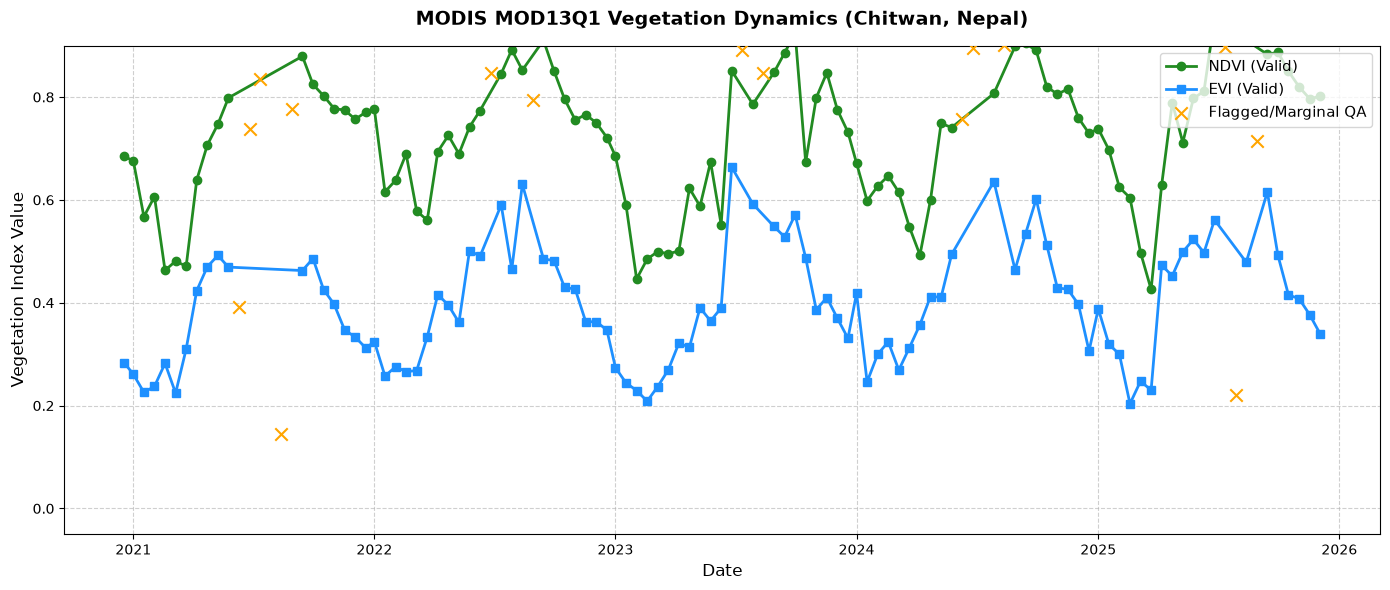

In [18]:
import matplotlib.pyplot as plt

# Separate Valid Data vs. Filtered/Low-Quality Data
# Reliability: 0 = Good, 1 = Marginal. Anything else (or -1) is low quality/missing.
valid_mask = df[qa_col].isin([0, 1])

valid_df = df[valid_mask]
invalid_df = df[~valid_mask]

# Create the Plot
plt.figure(figsize=(14, 6))

# Plot NDVI line and points
plt.plot(valid_df['Date'], valid_df['Clean_NDVI'], label='NDVI (Valid)', color='forestgreen', marker='o', linestyle='-', linewidth=2)

# Plot EVI line and points
plt.plot(valid_df['Date'], valid_df['Clean_EVI'], label='EVI (Valid)', color='dodgerblue', marker='s', linestyle='-', linewidth=2)

# Highlight flagged or missing quality points on the NDVI line for visibility
if len(invalid_df) > 0:
    plt.scatter(invalid_df['Date'], invalid_df['Clean_NDVI'], color='orange', marker='x', s=80, label='Flagged/Marginal QA', zorder=5)

# 5. Styling and Labels
plt.title(f"MODIS MOD13Q1 Vegetation Dynamics (Chitwan, Nepal)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Vegetation Index Value", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.ylim(-0.05, 0.9) # Vegetation indices range safely from 0 to 1
plt.legend(loc='upper right', fontsize=11)

plt.tight_layout()
plt.show()